In [2]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = ''

import pandas
import joblib

from ccs import ccs
import cellohood

ZENODO_PATH = '/raid/immucan/immuw/cellohood_artifacts/SPLEEN'

DATA_PATH = os.path.join(ZENODO_PATH, 'spleen.df')
data_df = pandas.read_csv(DATA_PATH)


MARKER_COL_NAMES = [
    'CD45', 
    'Ly6C', 
    'TCR', 
    'Ly6G', 
    'CD19', 
    'CD169', 
    'CD106', 
    'CD3', 
    'CD1632', 
    'CD8a', 
    'CD90', 
    'F480', 
    'CD11c', 
    'Ter119', 
    'CD11b', 
    'IgD', 
    'CD27', 
    'CD5', 
    'CD79b', 
    'CD71', 
    'CD31', 
    'CD4', 
    'IgM', 
    'B220', 
    'ERTR7', 
    'CD35', 
    'CD2135', 
    'CD44', 
    'NKp46', 
    'MHCII', 

]


POS_COL_NAMES = ['tile.X', 'tile.Y']
IMAGE_ID_COLUMN = 'sample'
SAMPLE_COL_NAME = 'sample'

LOAD_CELLO_BAG_DF = False
FULL_CELLO_BAG_DF_PATH_PREFIX = f'SpleenBCDf'

/tmp/ipykernel_3421932/1050061950.py:14: DtypeWarning: Columns (48,49) have mixed types. Specify dtype option on import or set low_memory=False.
  data_df = pandas.read_csv(DATA_PATH)


In [3]:
SAMPLES_TO_TEST = ['BALBc-3', 'MRL-5']

data_df = data_df[data_df[SAMPLE_COL_NAME].apply(lambda x: x in SAMPLES_TO_TEST)]

In [4]:
import numpy

STEP = 5.
MIN = 5.
MAX = 120.

DISTANCE_THRESHOLDS = numpy.arange(MIN, MAX + STEP, STEP)

In [5]:
data_df.shape

(157216, 52)

In [6]:
import tqdm 


for dt in tqdm.tqdm(DISTANCE_THRESHOLDS):
    bag_cello_df = cellohood.transform_df_to_bag_cello_df(
        df_=data_df,
        image_id_column=IMAGE_ID_COLUMN,
        pos_col_names=POS_COL_NAMES,
        distance_threshold=dt,
        marker_col_names=MARKER_COL_NAMES,
    )
    saving_path = f'{FULL_CELLO_BAG_DF_PATH_PREFIX}_{dt}'
    cellohood.save_bag_cello_df(bag_cello_df=bag_cello_df, path=saving_path, exist_ok=True)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 24/24 [4:31:10<00:00, 677.94s/it]


In [8]:
thresholds_to_sizes = {}


for dt in tqdm.tqdm(DISTANCE_THRESHOLDS):
    loading_path = f'{FULL_CELLO_BAG_DF_PATH_PREFIX}_{dt}'
    bag_cello_df = cellohood.load_bag_cello_df(loading_path)
    thresholds_to_sizes[dt] = bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster').size()

  0%|                                                                                                                                                                                          | 0/24 [00:00<?, ?it/s]/raid/immucan/immuw/cellohood/cellohood/data_processing/data_transforms.py:384: DtypeWarning: Columns (49,50) have mixed types. Specify dtype option on import or set low_memory=False.
  data_df = pandas.read_csv(df_path)
  4%|███████▍                                                                                                                                                                          | 1/24 [00:00<00:14,  1.63it/s]/raid/immucan/immuw/cellohood/cellohood/data_processing/data_transforms.py:384: DtypeWarning: Columns (49,50) have mixed types. Specify dtype option on import or set low_memory=False.
  data_df = pandas.read_csv(df_path)
  8%|██████████████▊                                                                                                              

 79%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏                                    | 19/24 [00:11<00:02,  1.67it/s]/raid/immucan/immuw/cellohood/cellohood/data_processing/data_transforms.py:384: DtypeWarning: Columns (49,50) have mixed types. Specify dtype option on import or set low_memory=False.
  data_df = pandas.read_csv(df_path)
 83%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌                             | 20/24 [00:11<00:02,  1.67it/s]/raid/immucan/immuw/cellohood/cellohood/data_processing/data_transforms.py:384: DtypeWarning: Columns (49,50) have mixed types. Specify dtype option on import or set low_memory=False.
  data_df = pandas.read_csv(df_path)
 88%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████

In [12]:
all_sizes = [
    val 
    for values in thresholds_to_sizes.values()
    for val in values.values
]

In [52]:
thresholds_to_nb_of_bags = {
    th: len(val)
    for th, val in thresholds_to_sizes.items()
}

In [14]:
print(max(all_sizes) - min(all_sizes) + 1)

16


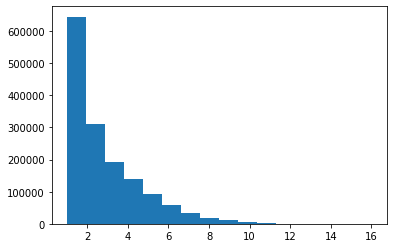

In [15]:
import matplotlib.pyplot as plt


_, bins, _ = plt.hist(all_sizes, bins=16)

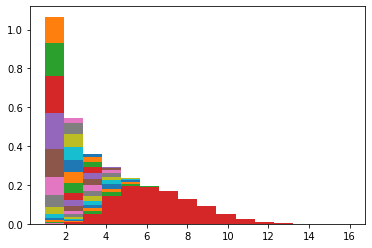

In [27]:
thresholds_to_bins = {}


for t, val in thresholds_to_sizes.items():
    counts_t, _, _ =  plt.hist(val.values, bins=bins, density=True)
    thresholds_to_bins[t] = counts_t

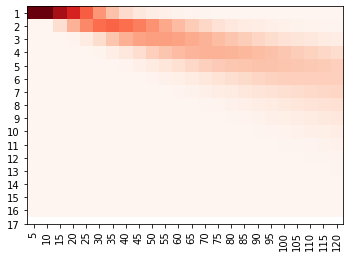

In [40]:
plt.imshow(numpy.array(list(thresholds_to_bins.values())).T, cmap='Reds')
ax = plt.gca()
_ = ax.set_xticks(numpy.arange(len(DISTANCE_THRESHOLDS)), labels=[int(i) for i in DISTANCE_THRESHOLDS], rotation=90)
_ = ax.set_yticks(numpy.arange(len(bins)), labels=[int(i) for i in numpy.arange(1, len(bins) + 1)])

In [43]:
thresholds_to_medians = {}
thresholds_to_means = {}
thresholds_to_stds = {}


for t, val in thresholds_to_sizes.items():
    thresholds_to_medians[t] = numpy.median(val.values)
    thresholds_to_means[t] = numpy.mean(val.values)
    thresholds_to_stds[t] = numpy.std(val.values)

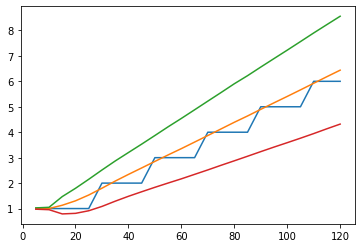

In [50]:
plt.plot(DISTANCE_THRESHOLDS, thresholds_to_medians.values())
plt.plot(DISTANCE_THRESHOLDS, thresholds_to_means.values())
plt.plot(DISTANCE_THRESHOLDS, numpy.array(list(thresholds_to_means.values())) + numpy.array(
    list(thresholds_to_stds.values())))
plt.plot(DISTANCE_THRESHOLDS, numpy.array(list(thresholds_to_means.values())) - numpy.array(
    list(thresholds_to_stds.values())))

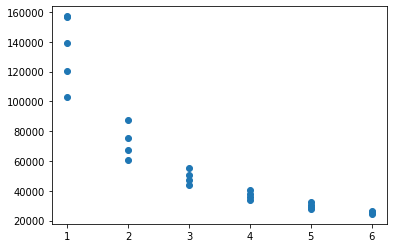

In [53]:
plt.scatter(thresholds_to_medians.values(), thresholds_to_nb_of_bags.values())

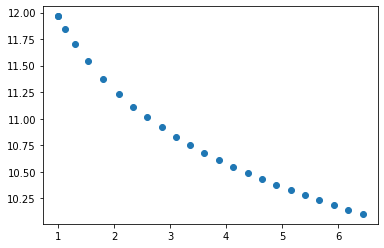

In [60]:
plt.scatter(thresholds_to_means.values(), numpy.log(numpy.array(list(thresholds_to_nb_of_bags.values()))))

In [153]:
from typing import List
from typing import Optional

import tqdm


MIN_DEFAULT_THRESHOLD = 10.
MAX_DEFAULT_THRESHOLD = 150.
DEFAULT_STEP = 10.

DEFAULT_CNC = 'cellohood_neighborhood_cluster'



def select_threshold_from_list(
    data_df, 
    image_id_column,
    pos_col_names,
    expected_size: float = 5., 
    method: str = 'median',
    thresholds: List[float] = None,
):
    if method == 'median':
        method = numpy.median
    elif method == 'mean':
        method = numpy.mean
        
    if thresholds is None:
        thresholds = numpy.arange(
            MIN_DEFAULT_THRESHOLD, 
            MAX_DEFAULT_THRESHOLD + DEFAULT_STEP,
            DEFAULT_STEP,
        )
        
    result_to_sizes = {}
        
    for threshold in tqdm.tqdm(thresholds):
        bag_cello_df = cellohood.transform_df_to_bag_cello_df(
            df_=data_df,
            image_id_column=image_id_column,
            pos_col_names=pos_col_names,
            distance_threshold=threshold,
            marker_col_names=[],
        )
        result_to_sizes[threshold] = list(
            bag_cello_df.cell_df.groupby(DEFAULT_CNC).size()
        )
        
    return result_to_sizes

In [154]:
res = select_threshold_from_list(data_df, image_id_column=IMAGE_ID_COLUMN, pos_col_names=POS_COL_NAMES)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15/15 [2:24:30<00:00, 578.04s/it]


In [203]:
res_spleen = res

In [204]:
res_to_mean_spleen = {threshold: numpy.mean(value) for threshold, value in res_spleen.items()}
res_to_median_spleen = {threshold: numpy.median(value) for threshold, value in res_spleen.items()}
res_to_max_spleen = {threshold: numpy.max(value) for threshold, value in res_spleen.items()}
res_to_std_spleen = {threshold: numpy.std(value) for threshold, value in res_spleen.items()}
res_to_size_spleen = {threshold: len(value) for threshold, value in res_spleen.items()}

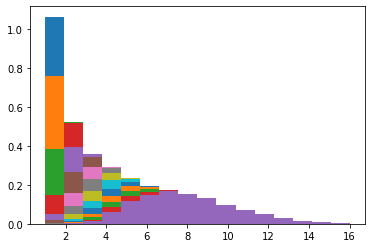

In [205]:
spleen_thresholds_to_bins = {}


for t, val in res_spleen.items():
    counts_t, _, _ =  plt.hist(val, bins=bins, density=True)
    spleen_thresholds_to_bins[t] = counts_t

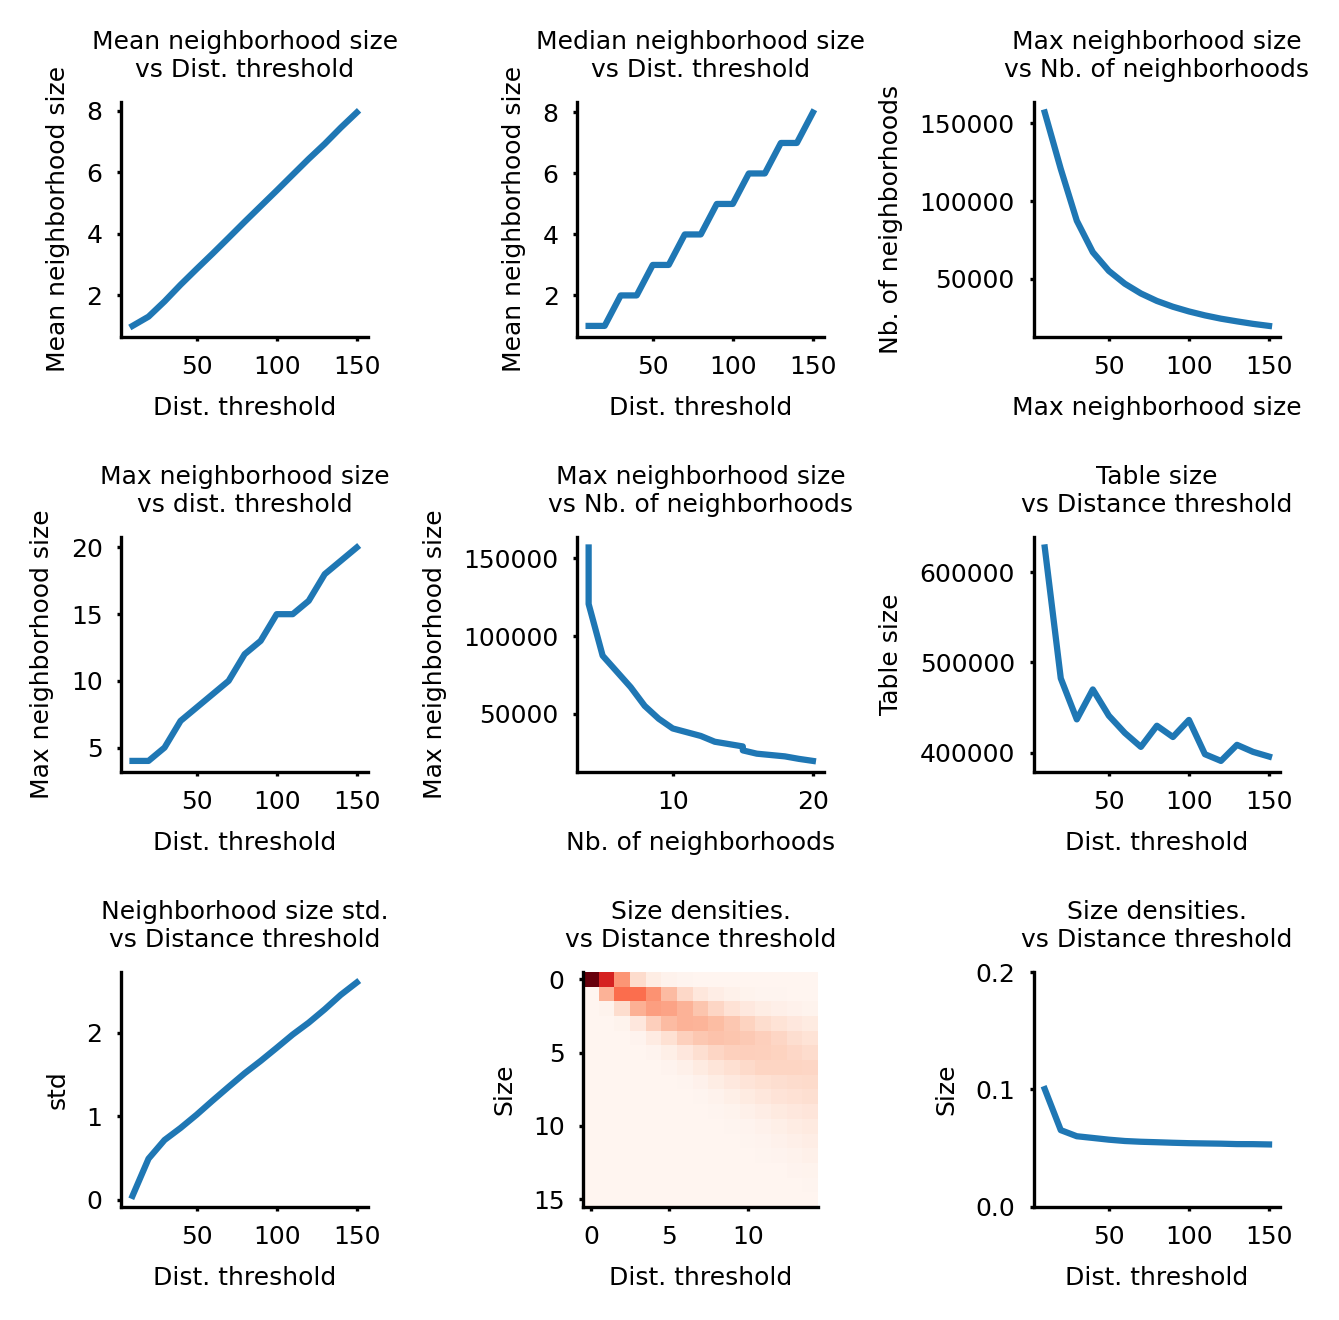

In [206]:
plt.figure(figsize=(4.5, 4.5), dpi=300)

plt.subplot(3, 3, 1)
plt.plot(res_to_mean_spleen.keys(), res_to_mean_spleen.values())
plt.title('Mean neighborhood size\nvs Dist. threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Mean neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

plt.subplot(3, 3, 2)
plt.plot(res_to_mean_spleen.keys(), res_to_median_spleen.values())
plt.title('Median neighborhood size\nvs Dist. threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Mean neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 3)
plt.plot(res_to_size_spleen.keys(), res_to_size_spleen.values())
plt.title('Max neighborhood size\nvs Nb. of neighborhoods', size=6)
plt.ylabel('Nb. of neighborhoods', size=6)
plt.xlabel('Max neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

plt.subplot(3, 3, 4)
plt.plot(res_to_max_spleen.keys(), res_to_max_spleen.values())
plt.title('Max neighborhood size\nvs dist. threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Max neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 5)
plt.plot(res_to_max_spleen.values(), res_to_size_spleen.values())
plt.title('Max neighborhood size\nvs Nb. of neighborhoods', size=6)
plt.xlabel('Nb. of neighborhoods', size=6)
plt.ylabel('Max neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 6)

table_sizes = numpy.array(list(res_to_size_spleen.values())) * numpy.array(list(res_to_max_spleen.values()))

plt.plot(res_to_max_spleen.keys(), table_sizes)
plt.title('Table size\nvs Distance threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Table size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 7)

table_sizes = numpy.array(list(res_to_size_spleen.values())) * numpy.array(list(res_to_max_spleen.values()))

plt.plot(res_to_std_spleen.keys(), res_to_std_spleen.values())
plt.title('Neighborhood size std.\nvs Distance threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('std', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

plt.subplot(3, 3, 8)

hist_vs_threshold = numpy.array(list(spleen_thresholds_to_bins.values())).T

plt.imshow(
    hist_vs_threshold, 
    cmap='Reds',
)
plt.title('Size densities.\nvs Distance threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)
ax.set_aspect(hist_vs_threshold.shape[1] / hist_vs_threshold.shape[0])

plt.subplot(3, 3, 9)

mean_to_ratios = numpy.array(list(res_to_mean_spleen.values())) / numpy.array(list(res_to_mean_spleen.keys()))

plt.title('Size densities.\nvs Distance threshold', size=6)
plt.plot(res_to_std_spleen.keys(), mean_to_ratios)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Size', size=6)
ax = plt.gca()
plt.ylim([0, max(mean_to_ratios) + 0.1])
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)
#ax.set_aspect(hist_vs_threshold.shape[1] / hist_vs_threshold.shape[0])

plt.tight_layout()

In [71]:
nsclc = pandas.read_csv('/raid/immucan/immuw/data/nsclc2_25_full.df')

/tmp/ipykernel_3421932/2977111053.py:1: DtypeWarning: Columns (15,83,84) have mixed types. Specify dtype option on import or set low_memory=False.
  nsclc = pandas.read_csv('/raid/immucan/immuw/data/nsclc2_25_full.df')


In [96]:
import random

nb_of_images = nsclc['image'].nunique()
images = random.sample(set(nsclc['image']), k=int(0.1 * nb_of_images))

In [97]:
nsclc_subset = nsclc[nsclc['image'].apply(lambda x: x in images)]

In [104]:
res_nsclc = select_threshold_from_list(nsclc_subset, image_id_column='image', pos_col_names=['Pos_X', 'Pos_Y'])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 46/46 [42:39<00:00, 55.63s/it]


In [200]:
res_to_mean_nsclc = {threshold: numpy.mean(value) for threshold, value in res_nsclc.items()}
res_to_median_nsclc = {threshold: numpy.median(value) for threshold, value in res_nsclc.items()}
res_to_max_nsclc = {threshold: numpy.max(value) for threshold, value in res_nsclc.items()}
res_to_std_nsclc = {threshold: numpy.std(value) for threshold, value in res_nsclc.items()}
res_to_size_nsclc = {threshold: len(value) for threshold, value in res_nsclc.items()}

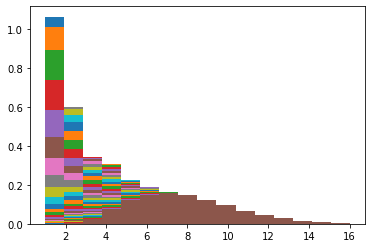

In [201]:
nsclc_thresholds_to_bins = {}


for t, val in res_nsclc.items():
    counts_t, _, _ =  plt.hist(val, bins=bins, density=True)
    nsclc_thresholds_to_bins[t] = counts_t

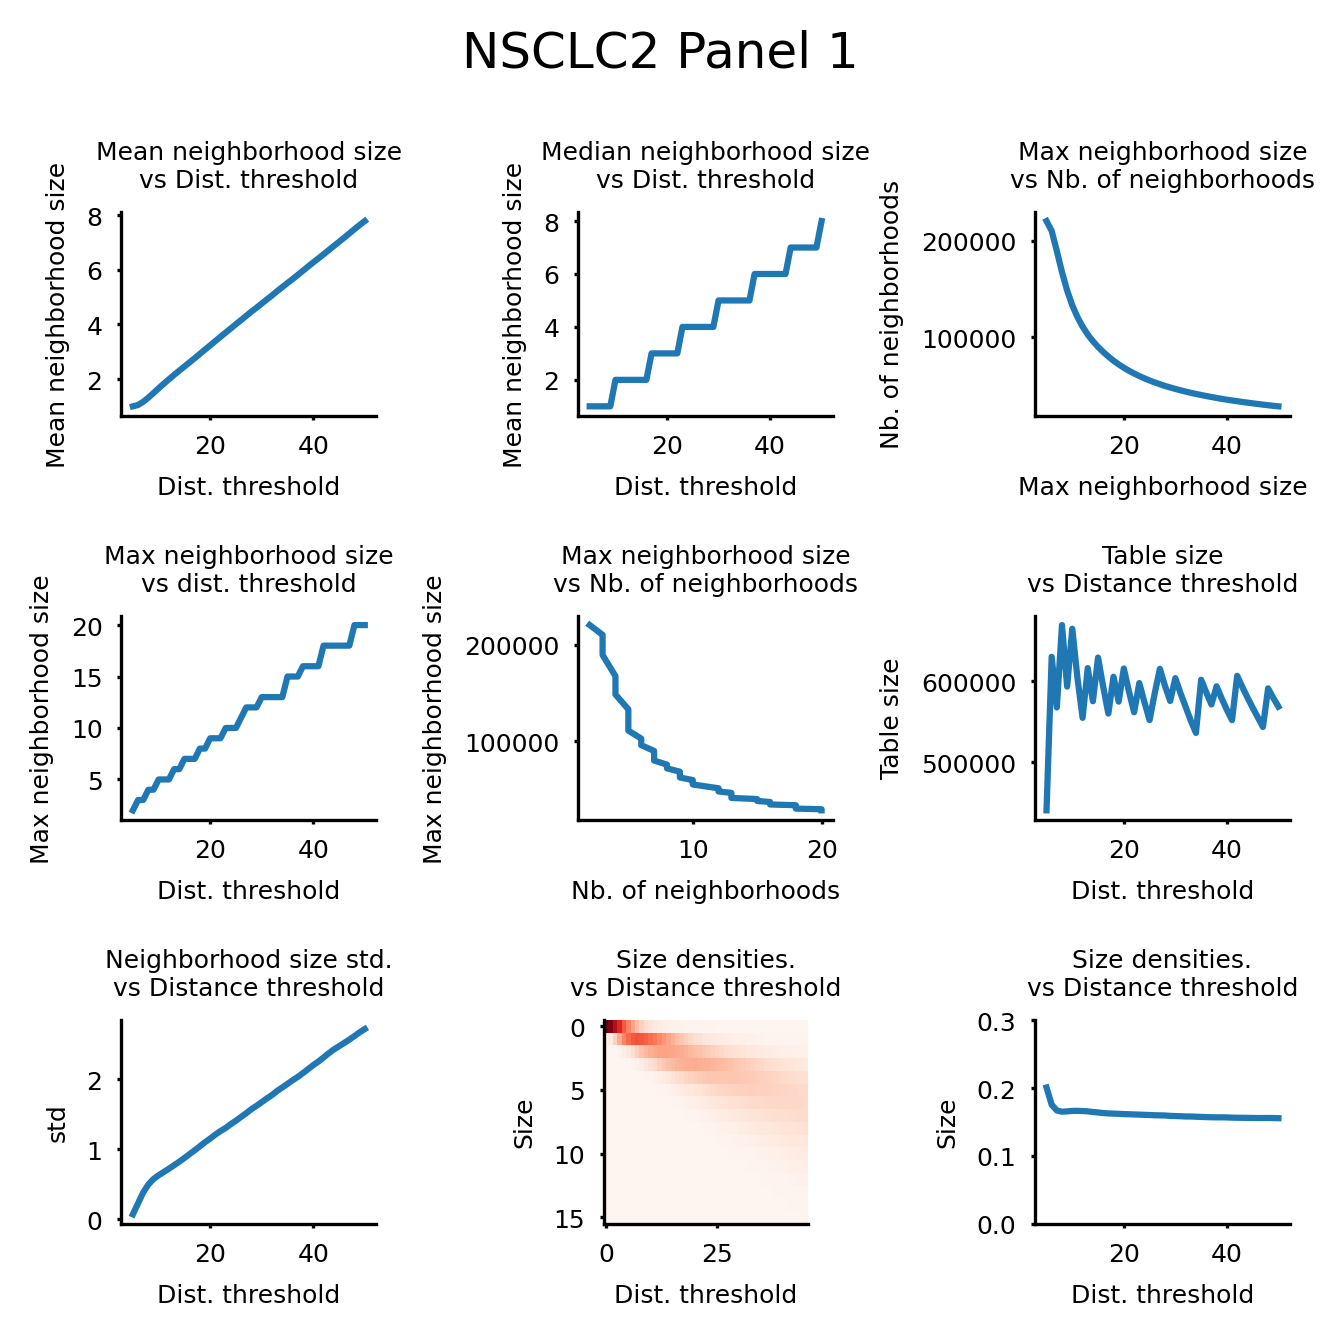

In [207]:
fig = plt.figure(figsize=(4.5, 4.5), dpi=300)
fig.suptitle('NSCLC2 Panel 1')

plt.subplot(3, 3, 1)
plt.plot(res_to_mean_nsclc.keys(), res_to_mean_nsclc.values())
plt.title('Mean neighborhood size\nvs Dist. threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Mean neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

plt.subplot(3, 3, 2)
plt.plot(res_to_mean_nsclc.keys(), res_to_median_nsclc.values())
plt.title('Median neighborhood size\nvs Dist. threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Mean neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 3)
plt.plot(res_to_size_nsclc.keys(), res_to_size_nsclc.values())
plt.title('Max neighborhood size\nvs Nb. of neighborhoods', size=6)
plt.ylabel('Nb. of neighborhoods', size=6)
plt.xlabel('Max neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

plt.subplot(3, 3, 4)
plt.plot(res_to_max_nsclc.keys(), res_to_max_nsclc.values())
plt.title('Max neighborhood size\nvs dist. threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Max neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 5)
plt.plot(res_to_max_nsclc.values(), res_to_size_nsclc.values())
plt.title('Max neighborhood size\nvs Nb. of neighborhoods', size=6)
plt.xlabel('Nb. of neighborhoods', size=6)
plt.ylabel('Max neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 6)

table_sizes = numpy.array(list(res_to_size_nsclc.values())) * numpy.array(list(res_to_max_nsclc.values()))

plt.plot(res_to_max_nsclc.keys(), table_sizes)
plt.title('Table size\nvs Distance threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Table size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 7)

table_sizes = numpy.array(list(res_to_size_nsclc.values())) * numpy.array(list(res_to_max_nsclc.values()))

plt.plot(res_to_std_nsclc.keys(), res_to_std_nsclc.values())
plt.title('Neighborhood size std.\nvs Distance threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('std', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

plt.subplot(3, 3, 8)

hist_vs_threshold = numpy.array(list(nsclc_thresholds_to_bins.values())).T

plt.imshow(
    hist_vs_threshold, 
    cmap='Reds',
)
plt.title('Size densities.\nvs Distance threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)
ax.set_aspect(hist_vs_threshold.shape[1] / hist_vs_threshold.shape[0])

plt.subplot(3, 3, 9)

mean_to_ratios = numpy.array(list(res_to_mean_nsclc.values())) / numpy.array(list(res_to_mean_nsclc.keys()))

plt.title('Size densities.\nvs Distance threshold', size=6)
plt.plot(res_to_std_nsclc.keys(), mean_to_ratios)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Size', size=6)
ax = plt.gca()
plt.ylim([0, max(mean_to_ratios) + 0.1])
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)
#ax.set_aspect(hist_vs_threshold.shape[1] / hist_vs_threshold.shape[0])

plt.tight_layout()

In [109]:
jackson = pandas.read_csv('/raid/immucan/immuw/data/jackson_25.df')

In [128]:
nb_of_images = jackson['sample'].nunique()
jackson_images = random.sample(set(jackson['sample']), k=int(0.1 * nb_of_images))

In [131]:
jackson_subset = jackson[jackson['sample'].apply(lambda x: x in jackson_images)]

In [135]:
res_jackson = select_threshold_from_list(jackson_subset, image_id_column='sample', pos_col_names=['Location_Center_X', 'Location_Center_Y'])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 46/46 [15:53<00:00, 20.73s/it]


In [197]:
res_to_mean_jackson = {threshold: numpy.mean(value) for threshold, value in res_jackson.items()}
res_to_median_jackson = {threshold: numpy.median(value) for threshold, value in res_jackson.items()}
res_to_max_jackson = {threshold: numpy.max(value) for threshold, value in res_jackson.items()}
res_to_std_jackson = {threshold: numpy.std(value) for threshold, value in res_jackson.items()}
res_to_size_jackson = {threshold: len(value) for threshold, value in res_jackson.items()}

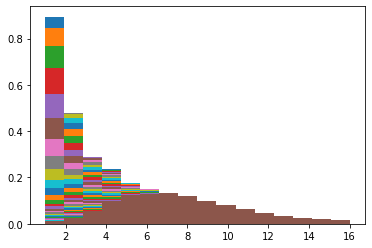

In [198]:
jackson_thresholds_to_bins = {}


for t, val in res_jackson.items():
    counts_t, _, _ =  plt.hist(val, bins=bins, density=True)
    jackson_thresholds_to_bins[t] = counts_t

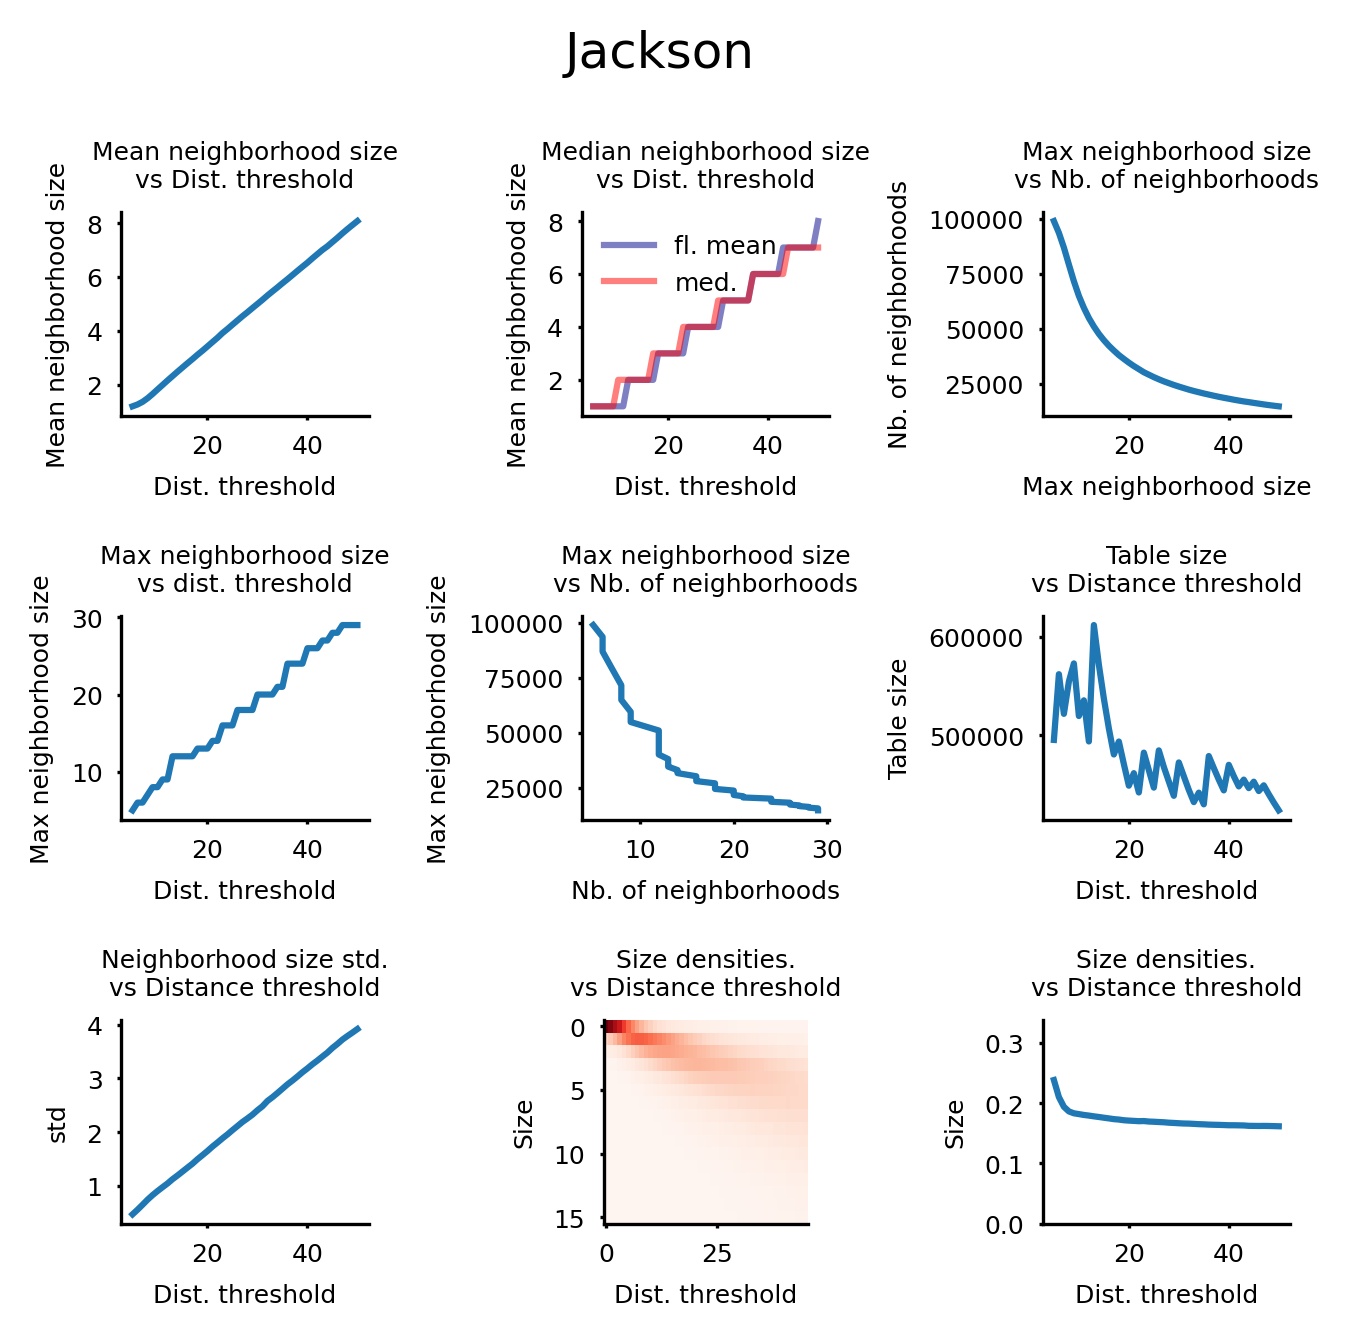

In [224]:
import math


fig = plt.figure(figsize=(4.5, 4.5), dpi=300)
fig.suptitle('Jackson')

plt.subplot(3, 3, 1)
plt.plot(res_to_mean_jackson.keys(), res_to_mean_jackson.values())
plt.title('Mean neighborhood size\nvs Dist. threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Mean neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

plt.subplot(3, 3, 2)
plt.plot(
    res_to_mean_jackson.keys(), 
    [math.floor(el) for el in res_to_mean_jackson.values()], 
    label='fl. mean',
    alpha=0.5,
    c='darkblue'
)
plt.plot(res_to_mean_jackson.keys(), res_to_median_jackson.values(), label='med.', alpha=0.5, c='red')
plt.title('Median neighborhood size\nvs Dist. threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Mean neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=6, frameon=False, markerscale=0.05, loc='upper left')


plt.subplot(3, 3, 3)
plt.plot(res_to_size_jackson.keys(), res_to_size_jackson.values())
plt.title('Max neighborhood size\nvs Nb. of neighborhoods', size=6)
plt.ylabel('Nb. of neighborhoods', size=6)
plt.xlabel('Max neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

plt.subplot(3, 3, 4)
plt.plot(res_to_max_jackson.keys(), res_to_max_jackson.values())
plt.title('Max neighborhood size\nvs dist. threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Max neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 5)
plt.plot(res_to_max_jackson.values(), res_to_size_jackson.values())
plt.title('Max neighborhood size\nvs Nb. of neighborhoods', size=6)
plt.xlabel('Nb. of neighborhoods', size=6)
plt.ylabel('Max neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 6)

table_sizes = numpy.array(list(res_to_size_jackson.values())) * numpy.array(list(res_to_max_jackson.values()))

plt.plot(res_to_max_jackson.keys(), table_sizes)
plt.title('Table size\nvs Distance threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Table size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 7)

table_sizes = numpy.array(list(res_to_size_jackson.values())) * numpy.array(list(res_to_max_jackson.values()))

plt.plot(res_to_std_jackson.keys(), res_to_std_jackson.values())
plt.title('Neighborhood size std.\nvs Distance threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('std', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

plt.subplot(3, 3, 8)

hist_vs_threshold = numpy.array(list(jackson_thresholds_to_bins.values())).T

plt.imshow(
    hist_vs_threshold, 
    cmap='Reds',
)
plt.title('Size densities.\nvs Distance threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)
ax.set_aspect(hist_vs_threshold.shape[1] / hist_vs_threshold.shape[0])

plt.subplot(3, 3, 9)

mean_to_ratios = numpy.array(list(res_to_mean_jackson.values())) / numpy.array(list(res_to_mean_jackson.keys()))

plt.title('Size densities.\nvs Distance threshold', size=6)
plt.plot(res_to_std_jackson.keys(), mean_to_ratios)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Size', size=6)
ax = plt.gca()
plt.ylim([0, max(mean_to_ratios) + 0.1])
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)
#ax.set_aspect(hist_vs_threshold.shape[1] / hist_vs_threshold.shape[0])

plt.tight_layout()

In [120]:
nsclc_p2 = pandas.read_csv('/raid/immucan/immuw/data/nsclc2_panel2_50.csv')

/tmp/ipykernel_3421932/345651536.py:1: DtypeWarning: Columns (39,84,85) have mixed types. Specify dtype option on import or set low_memory=False.
  nsclc_p2 = pandas.read_csv('/raid/immucan/immuw/data/nsclc2_panel2_50.csv')


In [122]:
nb_of_images = nsclc_p2['image'].nunique()
nsclc_p2_images = random.sample(set(nsclc_p2['image']), k=int(0.1 * nb_of_images))

In [142]:
nsclc_p2_subset = nsclc_p2[nsclc_p2['image'].apply(lambda x: x in nsclc_p2_images)]

In [143]:
res_nsclc_p2 = select_threshold_from_list(nsclc_p2_subset, image_id_column='image', pos_col_names=['Pos_X', 'Pos_Y'])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 46/46 [35:57<00:00, 46.89s/it]


In [180]:
res_to_mean_nsclc_p2 = {threshold: numpy.mean(value) for threshold, value in res_nsclc_p2.items()}
res_to_median_nsclc_p2 = {threshold: numpy.median(value) for threshold, value in res_nsclc_p2.items()}
res_to_max_nsclc_p2 = {threshold: numpy.max(value) for threshold, value in res_nsclc_p2.items()}
res_to_std_nsclc_p2 = {threshold: numpy.std(value) for threshold, value in res_nsclc_p2.items()}
res_to_size_nsclc_p2 = {threshold: len(value) for threshold, value in res_nsclc_p2.items()}

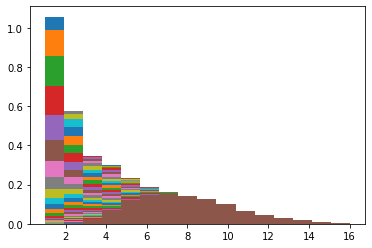

In [183]:
nsclc_p2_thresholds_to_bins = {}


for t, val in res_nsclc_p2.items():
    counts_t, _, _ =  plt.hist(val, bins=bins, density=True)
    nsclc_p2_thresholds_to_bins[t] = counts_t

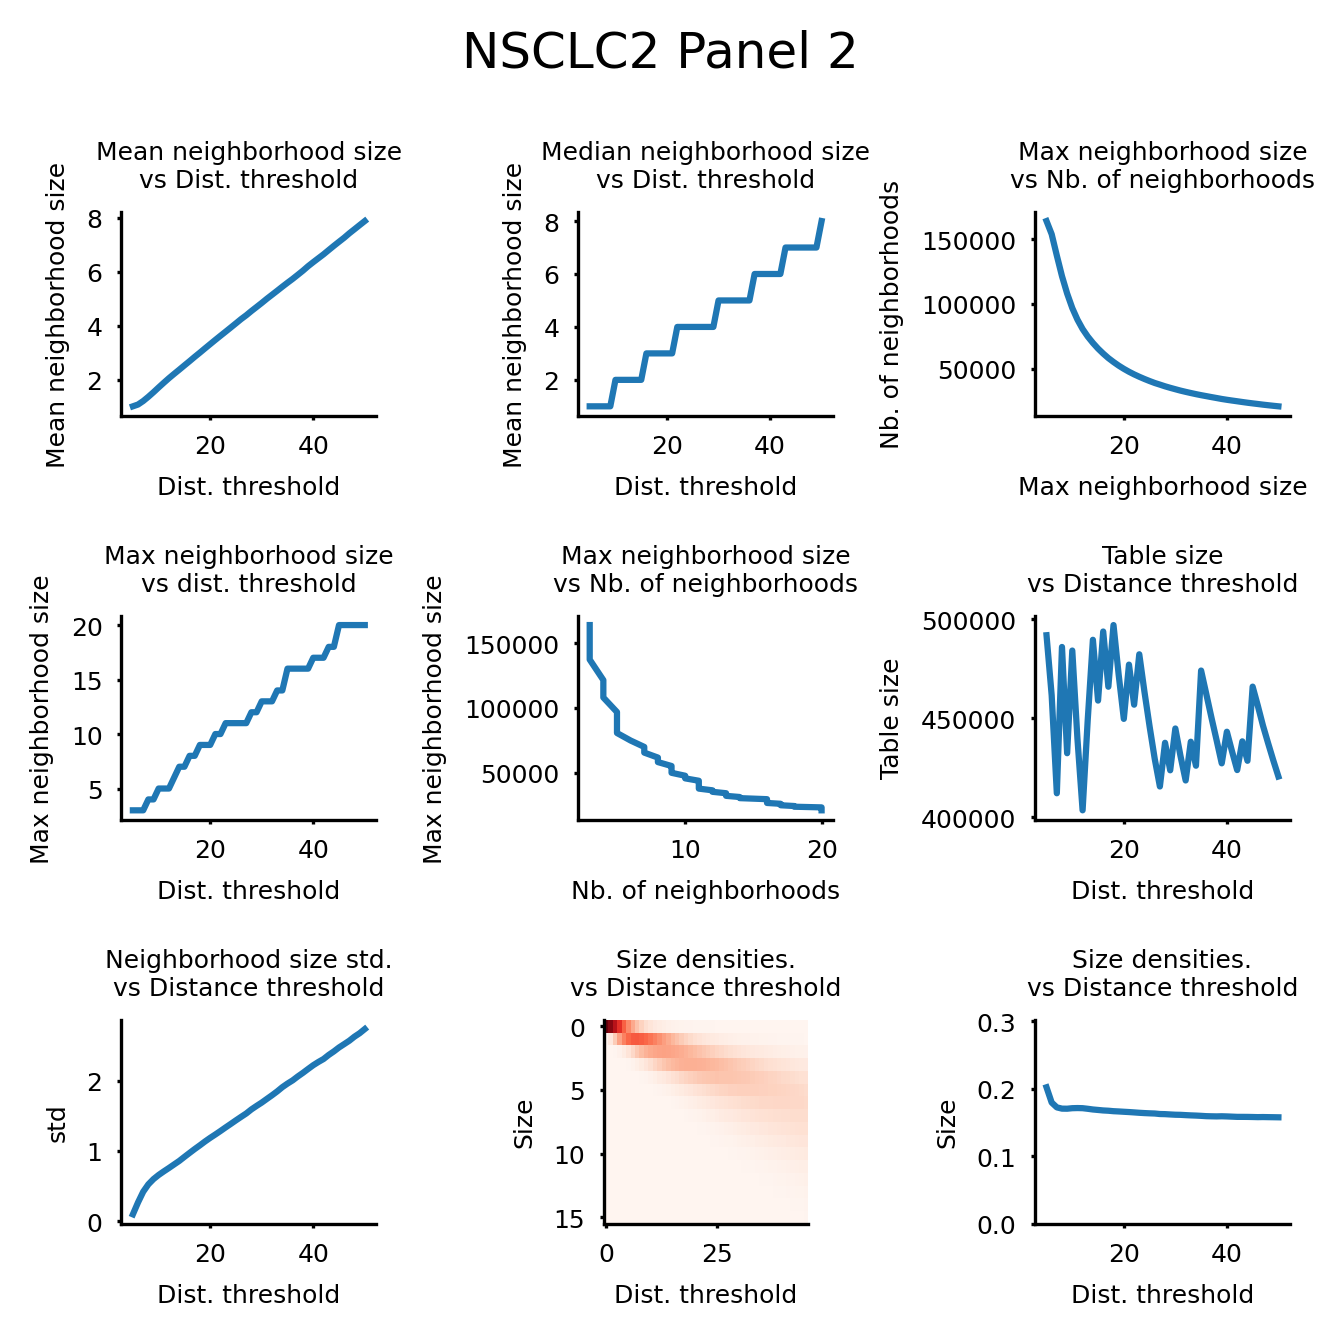

In [209]:
fig = plt.figure(figsize=(4.5, 4.5), dpi=300)

fig.suptitle('NSCLC2 Panel 2')

plt.subplot(3, 3, 1)
plt.plot(res_to_mean_nsclc_p2.keys(), res_to_mean_nsclc_p2.values())
plt.title('Mean neighborhood size\nvs Dist. threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Mean neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

plt.subplot(3, 3, 2)
plt.plot(res_to_mean_nsclc_p2.keys(), res_to_median_nsclc_p2.values())
plt.title('Median neighborhood size\nvs Dist. threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Mean neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 3)
plt.plot(res_to_size_nsclc_p2.keys(), res_to_size_nsclc_p2.values())
plt.title('Max neighborhood size\nvs Nb. of neighborhoods', size=6)
plt.ylabel('Nb. of neighborhoods', size=6)
plt.xlabel('Max neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

plt.subplot(3, 3, 4)
plt.plot(res_to_max_nsclc_p2.keys(), res_to_max_nsclc_p2.values())
plt.title('Max neighborhood size\nvs dist. threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Max neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 5)
plt.plot(res_to_max_nsclc_p2.values(), res_to_size_nsclc_p2.values())
plt.title('Max neighborhood size\nvs Nb. of neighborhoods', size=6)
plt.xlabel('Nb. of neighborhoods', size=6)
plt.ylabel('Max neighborhood size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 6)

table_sizes = numpy.array(list(res_to_size_nsclc_p2.values())) * numpy.array(list(res_to_max_nsclc_p2.values()))

plt.plot(res_to_max_nsclc_p2.keys(), table_sizes)
plt.title('Table size\nvs Distance threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Table size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)


plt.subplot(3, 3, 7)

table_sizes = numpy.array(list(res_to_size_nsclc_p2.values())) * numpy.array(list(res_to_max_nsclc_p2.values()))

plt.plot(res_to_std_nsclc_p2.keys(), res_to_std_nsclc_p2.values())
plt.title('Neighborhood size std.\nvs Distance threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('std', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)

plt.subplot(3, 3, 8)

hist_vs_threshold = numpy.array(list(nsclc_p2_thresholds_to_bins.values())).T

plt.imshow(
    hist_vs_threshold, 
    cmap='Reds',
)
plt.title('Size densities.\nvs Distance threshold', size=6)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Size', size=6)
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)
ax.set_aspect(hist_vs_threshold.shape[1] / hist_vs_threshold.shape[0])

plt.subplot(3, 3, 9)

mean_to_ratios = numpy.array(list(res_to_mean_nsclc_p2.values())) / numpy.array(list(res_to_mean_nsclc_p2.keys()))

plt.title('Size densities.\nvs Distance threshold', size=6)
plt.plot(res_to_std_nsclc_p2.keys(), mean_to_ratios)
plt.xlabel('Dist. threshold', size=6)
plt.ylabel('Size', size=6)
ax = plt.gca()
plt.ylim([0, max(mean_to_ratios) + 0.1])
ax.xaxis.set_tick_params(size=1, labelsize=6)
ax.yaxis.set_tick_params(size=1, labelsize=6)
ax.spines[['top', 'right']].set_visible(False)
#ax.set_aspect(hist_vs_threshold.shape[1] / hist_vs_threshold.shape[0])

plt.tight_layout()